In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Load dataset directly (avoiding the faulty merge from the previous version)
df = pd.read_csv('songs.csv')
print(f"Dataset shape: {df.shape}")
df.head(3)

Dataset shape: (491632, 24)


,id,name,album_name,artists,danceability,energy,key,loudness,mode,speechiness,...,tempo,duration_ms,lyrics,year,genre,popularity,total_artist_followers,avg_artist_popularity,artist_ids,niche_genres
0,2ASl4wirkeYm3OWZxXKYuq,!!,Childhood Dreams,"[""Yxngxr1""]",0.788,0.648,7,-9.135,0,0.315,...,79.998,114000,"Fuck the bitch, now she running with my kids\n...",2019,Hip-Hop,29,143628,45.0,"[""2jwRHcdgkRhelYEMqndDKe""]",[]
1,5tA3ImW310llKo8EMBj2Ga,!!Noble Stabbings!!,Situationist Comedy,"[""Dillinger Four""]",0.171,0.957,2,-5.749,1,0.149,...,175.317,197400,You like to stand on the other side\nPoint and...,2002,Rock,0,36619,35.0,"[""4YAN46l70QV0PGXlMg0iHi""]","[""melodic hardcore"", ""pop punk"", ""punk"", ""skat..."
2,0fROT4kK5oTm8xO8PX6EJF,!I'll Be Back!,!I'll Be Back!,"[""Ril\u00e8s""]",0.823,0.612,1,-7.767,1,0.248,...,142.959,178533,"It's been a while, shit, I missed the rehab, p...",2018,Hip-Hop,43,929303,63.0,"[""6pdcQa7by8IKuoVXvgknlI""]","[""french rap""]"


70th Percentile Popularity Score (Train): 28.0


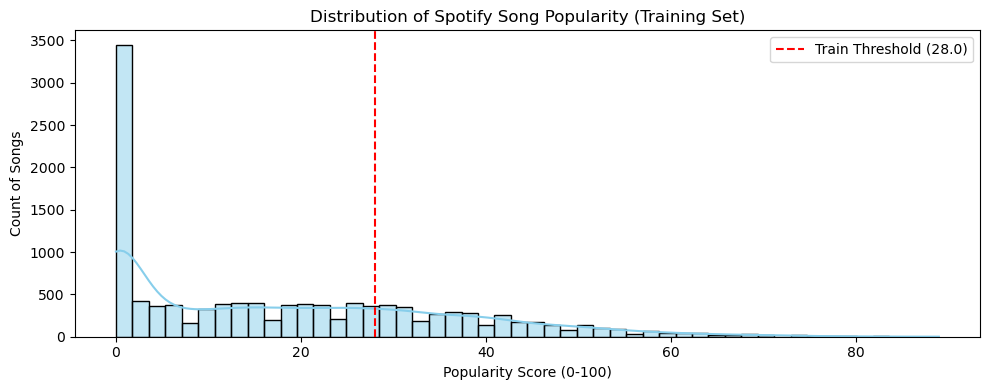

In [2]:
# Sample 15,000 songs
df_sampled = df.sample(n=15000, random_state=42).reset_index(drop=True)

# Split into Train and Test FIRST before any statistical calculations or encoding
train_df, test_df = train_test_split(df_sampled, test_size=0.2, random_state=42)

# Calculate 70th percentile ONLY on Training data to prevent leakage
percentile_70 = train_df['popularity'].quantile(0.70)
print(f"70th Percentile Popularity Score (Train): {percentile_70}")

# Create binary target for both sets using the train threshold
y_train = (train_df['popularity'] >= percentile_70).astype(int)
y_test = (test_df['popularity'] >= percentile_70).astype(int)

# Plot distribution on Training data
plt.figure(figsize=(10, 4))
sns.histplot(train_df['popularity'], bins=50, kde=True, color='skyblue')
plt.axvline(percentile_70, color='red', linestyle='--', label=f'Train Threshold ({percentile_70})')
plt.title('Distribution of Spotify Song Popularity (Training Set)')
plt.xlabel('Popularity Score (0-100)')
plt.ylabel('Count of Songs')
plt.legend()
plt.tight_layout()
plt.show()

In [3]:
# 1. One-Hot Encoding for main 'genre'
train_genre = pd.get_dummies(train_df['genre'], prefix='genre', dtype=int)
test_genre = pd.get_dummies(test_df['genre'], prefix='genre', dtype=int)
# Align columns so Test has the exact same genre columns as Train
train_genre, test_genre = train_genre.align(test_genre, join='left', axis=1, fill_value=0)

# 2. Extract Top 15 'niche_genres' based ONLY on Training data
def parse_niche(val):
    try:
        return ast.literal_eval(val) if isinstance(val, str) else []
    except:
        return []

train_niches = train_df['niche_genres'].apply(parse_niche)
test_niches = test_df['niche_genres'].apply(parse_niche)

# Find top 15 niches in Train only
all_train_niches = pd.Series([g for sublist in train_niches for g in sublist])
top_15_niches = all_train_niches.value_counts().head(15).index.tolist()

def encode_niches(parsed_series, top_niches):
    dummies = pd.DataFrame(0, index=parsed_series.index, columns=[f"niche_{g}" for g in top_niches])
    for idx, genres_list in parsed_series.items():
        for g in genres_list:
            if g in top_niches:
                dummies.loc[idx, f"niche_{g}"] = 1
    return dummies

train_niche_dummies = encode_niches(train_niches, top_15_niches)
test_niche_dummies = encode_niches(test_niches, top_15_niches)

# 3. Combine with numerical features
num_features = [
    'year', 'danceability', 'energy', 'key', 'loudness', 'mode', 
    'speechiness', 'acousticness', 'instrumentalness', 'liveness', 
    'valence', 'tempo', 'duration_ms', 'avg_artist_popularity'
]

X_train_raw = pd.concat([train_df[num_features], train_genre, train_niche_dummies], axis=1)
X_test_raw = pd.concat([test_df[num_features], test_genre, test_niche_dummies], axis=1)

print(f"Total features: {X_train_raw.shape[1]}")

Total features: 39


In [4]:
# Impute missing values (Fit on Train, Transform on Test)
imputer = SimpleImputer(strategy='mean')
X_train_imputed = imputer.fit_transform(X_train_raw)
X_test_imputed = imputer.transform(X_test_raw)

# Normalize features (Fit on Train, Transform on Test)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_imputed), columns=X_train_raw.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_imputed), columns=X_test_raw.columns)

# Train Decision Tree Classifier
clf = DecisionTreeClassifier(criterion='entropy', max_depth=4, class_weight='balanced', random_state=42)
clf.fit(X_train_scaled, y_train)

# Predictions
y_pred = clf.predict(X_test_scaled)

print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.84      0.59      0.69      2110
           1       0.43      0.73      0.54       890

    accuracy                           0.63      3000
   macro avg       0.63      0.66      0.62      3000
weighted avg       0.72      0.63      0.65      3000



In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score

# 1. Random Forest: 300 trees that vote together
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                            n_jobs=-1, random_state=42)

# 2. Choose the threshold using the TRAIN set only (cross-validation)
train_probs = cross_val_predict(rf, X_train_scaled, y_train, cv=5,
                                method='predict_proba')[:, 1]
print("--- Threshold table (train, cross-validated) ---")
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = train_probs >= t
    print(f"threshold {t}: precision={precision_score(y_train, pred, zero_division=0):.2f}, "
          f"share of songs recommended={pred.mean():.1%}")

# 3. Train on the full train set and evaluate on test
rf.fit(X_train_scaled, y_train)
probs = rf.predict_proba(X_test_scaled)[:, 1]

chosen = 0.5   # <- change this after looking at the table above
pred_test = probs >= chosen
print(f"\n--- Test results at threshold {chosen} ---")
print("Precision:", round(precision_score(y_test, pred_test, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, pred_test), 3))
print("Songs recommended:", pred_test.sum(), "out of", len(y_test))

# 4. Precision@100: of the 100 top-ranked songs, how many were real hits?
top_k = np.argsort(probs)[::-1][:100]
print("Precision@100:", y_test.iloc[top_k].mean())

--- Threshold table (train, cross-validated) ---
threshold 0.3: precision=0.45, share of songs recommended=47.6%
threshold 0.4: precision=0.54, share of songs recommended=26.6%
threshold 0.5: precision=0.63, share of songs recommended=9.7%
threshold 0.6: precision=0.68, share of songs recommended=1.3%
threshold 0.7: precision=0.00, share of songs recommended=0.0%

--- Test results at threshold 0.5 ---
Precision: 0.584
Recall: 0.21
Songs recommended: 320 out of 3000
Precision@100: 0.57


              precision    recall  f1-score   support

 Not Popular       0.74      0.94      0.83      2110
     Popular       0.58      0.21      0.31       890

    accuracy                           0.72      3000
   macro avg       0.66      0.57      0.57      3000
weighted avg       0.69      0.72      0.67      3000



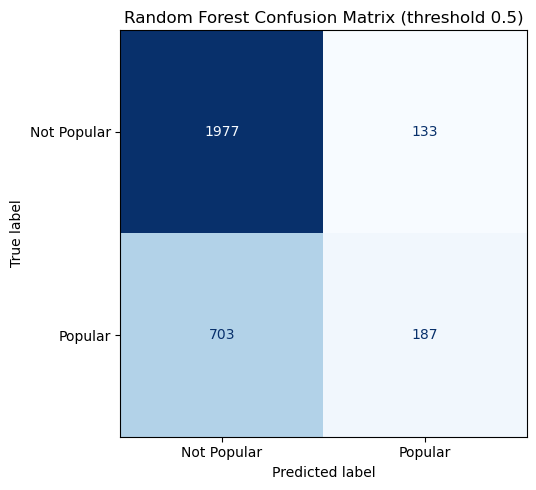

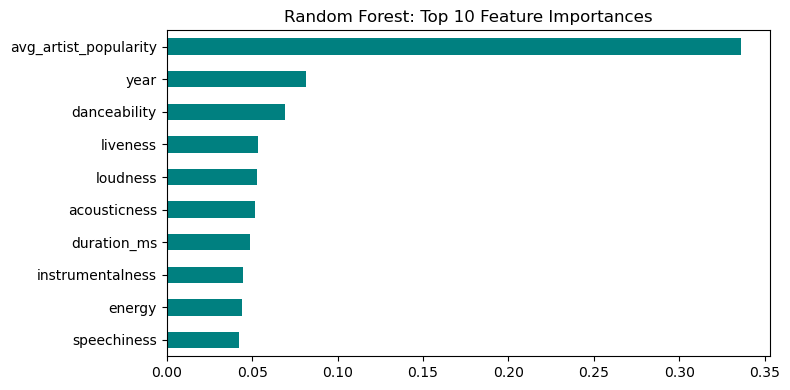

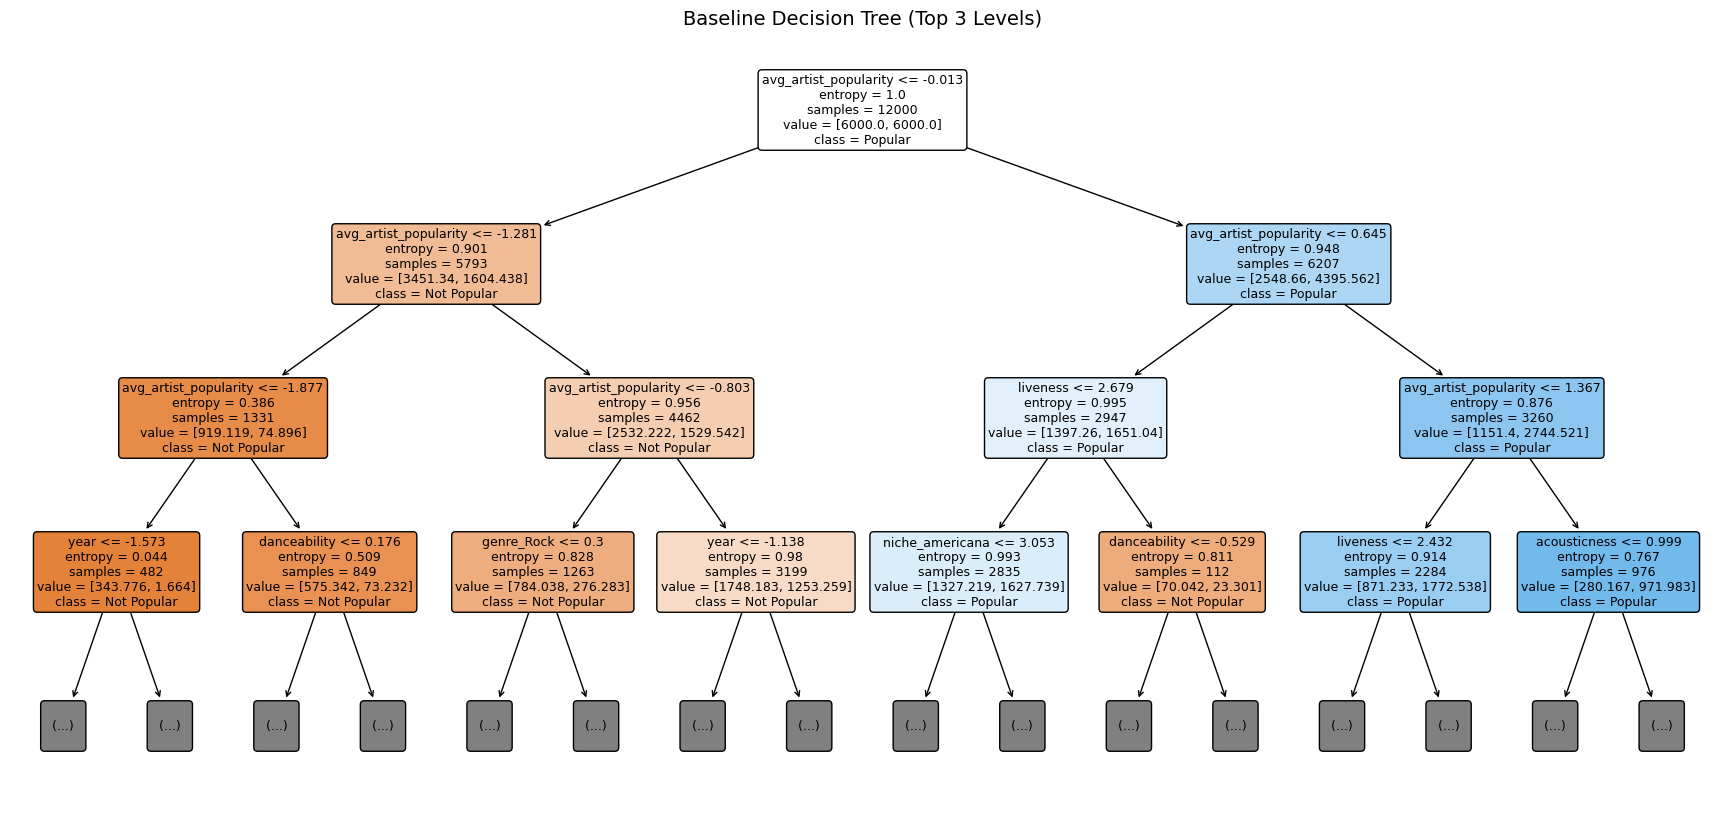

In [10]:
print(classification_report(y_test, pred_test, target_names=['Not Popular', 'Popular']))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test),
                       display_labels=['Not Popular', 'Popular']).plot(
    cmap='Blues', values_format='d', ax=ax, colorbar=False)
ax.set_title(f'Random Forest Confusion Matrix (threshold {chosen})')
plt.tight_layout()
plt.savefig('confusion_matrix_rf.png', dpi=150)
plt.show()

rf_imp = pd.Series(rf.feature_importances_, index=X_train_raw.columns).nlargest(10).sort_values()
rf_imp.plot(kind='barh', color='teal', figsize=(8, 4))
plt.title('Random Forest: Top 10 Feature Importances')
plt.tight_layout()
plt.savefig('feature_importance_rf.png', dpi=150)
plt.show()

plt.figure(figsize=(22, 10))
plot_tree(
    clf,
    feature_names=X_train_raw.columns.tolist(),
    class_names=['Not Popular', 'Popular'],
    filled=True, rounded=True, fontsize=9,
    max_depth=3
)
plt.title("Baseline Decision Tree (Top 3 Levels)", fontsize=14)
plt.savefig('decision_tree_baseline.png', dpi=120, bbox_inches='tight')
plt.show()